1. # Practical 2 report: from relationships to predictive models

**Student:** Valeriia  
**Date:** 25/10/2026   
**Practical:** 2 - Regression and evaluation


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import dcor
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml, load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 240926

In [2]:
diabetes = load_diabetes(as_frame=True).frame

# The age feature is standardized; qcut creates relative low/middle/high groups.
diabetes["sex"] = pd.Categorical(
    np.where(diabetes["sex"] > 0, "sex_1", "sex_2"),
    categories=["sex_1", "sex_2"],
)
diabetes["age_group"] = pd.qcut(
    diabetes["age"], q=3, labels=["young", "adult", "senior"]
)

diabetes.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target,age_group
0,0.038076,sex_1,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0,senior
1,-0.001882,sex_2,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0,adult
2,0.085299,sex_1,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0,senior
3,-0.089063,sex_2,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0,young
4,0.005383,sex_2,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0,adult


In [9]:
diabetes.shape

(442, 12)

In [24]:
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   age        442 non-null    float64 
 1   sex        442 non-null    category
 2   bmi        442 non-null    float64 
 3   bp         442 non-null    float64 
 4   s1         442 non-null    float64 
 5   s2         442 non-null    float64 
 6   s3         442 non-null    float64 
 7   s4         442 non-null    float64 
 8   s5         442 non-null    float64 
 9   s6         442 non-null    float64 
 10  target     442 non-null    float64 
 11  age_group  442 non-null    category
dtypes: category(2), float64(10)
memory usage: 35.8 KB


## 2. Data-preparation readiness

Complete the checklist before describing modelling results. Tick an item only after checking the data or documenting a justified decision.

### Scientific purpose and provenance

- [X] Is the biological question and prediction task stated clearly? `To predict how physiological parameters impact targed score aka disease progression.`
- [X] Is the unit of observation clear? `All the measurments are normalized, so they don't have units. Age and sex were converted manually to categorical types.`
- [X] Do I know where the data came from, how they were generated, and under which access conditions they may be used? `From the sklearn library.`
- [X] Have I recorded the data version, processing history, and transformations already applied? `They are in the sklearn documentation.`

### Table shape and identifiers

- [X] Is the table tidy: one observation per row, one variable per column, and one value per cell? `Yes.`
- [X] If needed, have I transposed the original assay into the format expected by the analysis tool? `Was already done.`
- [X] Are row names, column names, and identifiers clear, unique, and stable? `Yes.`
- [X] Can every feature and observation be traced to its source? `yes, each column is a documented measurement (age, sex, BMI, blood pressure, six serum markers) in the sklearn dataset description. Observations: no. Patients are anonymous and there is no patient ID, only a row index.`
- [X] Are the feature matrix and metadata aligned by an explicit identifier rather than row order? `No identifier exists. Features, target and the derived metadata are columns of one table, so rows cannot become misaligned`

In [28]:
print("Shape:", diabetes.shape)
print("Column names are unique:", diabetes.columns.is_unique)

Shape: (442, 12)
Column names are unique: True


In [3]:
numeric_columns = diabetes.select_dtypes(include="number").columns.tolist()
categorical_columns = diabetes.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)
print("Constant columns:", [column for column in diabetes.columns if diabetes[column].nunique(dropna=False) <= 1])

Numeric columns: ['age', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']
Categorical columns: ['sex', 'age_group']
Constant columns: []


### Types, values, and measurement meaning

- [X] Are numerical, categorical, ordinal, text, date, and identifier columns correctly classified? `Yes.`
- [X] Are units, scales, encodings, reference categories, and detection limits understood? `Yes`
- [X] Have impossible values, inconsistent labels, unexpected categories, constant features, and extreme values been checked? `Yes.`
- [X] Are normalization, scaling, log transformation, and batch-correction steps documented? They should be in the sklearn documentation. `Documented by sklearn: each predictor is mean-centered and scaled by its standard deviation × √n, so each column has sum of squares 1. The target is not scaled (range 25–346). No batch correction is documented. Because scaling was done on all 442 patients before my split, the test set influenced the scaling slightly.`

In [96]:
meta_cols = ["sex", "age_group"]
measured_cols = [c for c in diabetes.columns if c not in meta_cols]
X_all = diabetes[measured_cols]
predictors = X_all.drop(columns="target")

print("Infinite values:", int(np.isinf(X_all.to_numpy(dtype=float)).sum()),
      "| zeros:", int((predictors == 0).sum().sum()),
      "| constant columns:", int((X_all.nunique() <= 1).sum()))
print("Negative values in predictors:", int((predictors < 0).sum().sum()))
print("Negative values in target:", int((X_all["target"] < 0).sum()))
print("Predictor range:", round(float(predictors.min().min()), 3),
      "to", round(float(predictors.max().max()), 3))
print("Target range:", X_all["target"].min(), "to", X_all["target"].max())

display(predictors.describe().T[["min", "50%", "max"]].sort_values("max", ascending=False).round(3))

Infinite values: 0 | zeros: 0 | constant columns: 0
Negative values in predictors: 2157
Negative values in target: 0
Predictor range: -0.138 to 0.199
Target range: 25.0 to 346.0


,min,50%,max
s2,-0.116,-0.004,0.199
s4,-0.076,-0.003,0.185
s3,-0.102,-0.007,0.181
bmi,-0.090,-0.007,0.171
s1,-0.127,-0.004,0.154
s6,-0.138,-0.001,0.136
s5,-0.126,-0.002,0.134
bp,-0.112,-0.006,0.132
age,-0.107,0.005,0.111


In [35]:
print("Categorical levels:", {c: sorted(diabetes[c].unique()) for c in meta_cols})

Categorical levels: {'sex': ['sex_1', 'sex_2'], 'age_group': ['adult', 'senior', 'young']}


### Missing values

- [X] Have missing values been detected using all representations, not only `NaN`? `No missing values.`
- [X] Have missing values been measured by row, column, and relevant group? `No missing values.`
- [X] Do I know whether missingness is structural, technical, or plausibly related to biology or the target? `No missing values.`
- [X] Have retention, removal, or imputation been justified? `No missing values.`
- [X] If imputing, will the imputer be fitted on training data only? `No missing values.`

In [5]:
missing_by_column = X_all.isna().sum().sort_values(ascending=False)
missing_by_row = X_all.isna().sum(axis=1)

display(missing_by_column.to_frame("missing_count"))
display((missing_by_column / len(diabetes)).to_frame("missing_fraction"))
print("Rows with at least one missing value:", int((missing_by_row > 0).sum()))
print("Rows with more than one missing value:", int((missing_by_row > 1).sum()))

,missing_count
age,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0
target,0


,missing_fraction
age,0.0
bmi,0.0
bp,0.0
s1,0.0
s2,0.0
s3,0.0
s4,0.0
s5,0.0
s6,0.0
target,0.0


Rows with at least one missing value: 0
Rows with more than one missing value: 0


### Replicates, dependence, and grouping

- [X] Have exact and near-duplicate observations been checked? `No replicates.`
- [X] Are observations biological replicates, technical replicates, repeated measurements, pseudo-replicates, or independent samples? `No replicates.`
- [X] Is the independent biological unit identified by a grouping variable? `No grouping variable exists.`
- [X] Will related observations remain in the same train/validation/test split? `No related observations are known, so a random row-wise split is acceptable`
- [X] Is the provenance of synthetic or augmented observations recorded? `No synthetic or augmented data are used. These are real patient measurements, and I did not augment them.`

In [42]:
print("Exact duplicate rows", int(diabetes.duplicated().sum()))

for column in ["age_group", "sex"]:
    print(f"\nCounts for {column}:")
    display(diabetes[column].value_counts(dropna=False).to_frame("count"))

Exact duplicate rows 0

Counts for age_group:


,count
age_group,
adult,152
young,147
senior,143



Counts for sex:


,count
sex,
sex_2,235
sex_1,207


In [43]:
print("\nCounts by age and sex:")
display(diabetes.groupby(["age_group", "sex"], observed=False).size().rename("count").to_frame())


Counts by age and sex:


count
age_group sex         
young     sex_1     57
          sex_2     90
adult     sex_1     63
          sex_2     89
senior    sex_1     87
          sex_2     56

### Target, leakage, confounding, and reproducibility

- [X] Is the target defined before modelling? `Yes.`
- [X] Have identifiers, post-outcome variables, duplicated target information, and other leakage sources been excluded? `No target leakage found`
- [ ] Have batch, site, subject, treatment, sex, age, time, and other possible confounders been considered? Yes ( like I had just to find that there are some kinds of possible confounders?) `Age and sex were considered (mean target differs by age group: 136 / 152 / 170 for young / adult / senior). BMI may affect both lipid markers and progression. Batch, site, time and treatment are not recorded, and treatment during the year is an unmeasured confounder.`
- [X] Does the planned split represent the biological generalization question? `The question is whether baseline measurements predict progression in new patients. A random 80/20 patient-level split fits this, since each row is a different patient`
- [X] Are random seeds, software versions, file names, shapes, and preprocessing decisions recorded? `Yes, in this notebook.`

**Preparation summary:**

- Biological unit: `one patient (a row)`
- Number of observations and features: `442 patients, 10 predictors plus the target`
- Target and feature definition: `Target - numerical disease progression score, featurs - physiologocsl measured parameters`
- Missing-value decision: `no missing values`
- Replicate/grouping decision: `no replicates`
- Main confounder or leakage source: `no leakage found`
- Train/test split and justification: `80/20 random split (random_state=240926) with 89 test patients, justified by independent rows`
- Remaining concerns: `multicollinearity among s1–s4, S4’s coarse values, mild heteroscedasticity, a single cohort, unrecorded treatment, and a small test set (added post factum)`

In [6]:
TARGET = "target"

for grouping_variable in ["age_group", "sex"]:
    print(f"\nTarget summary by {grouping_variable}:")
    display(diabetes.groupby(grouping_variable, observed=False)[TARGET].agg(["count", "mean", "std"]))


Target summary by age_group:


,count,mean,std
age_group,,,
young,147,135.639456,71.898325
adult,152,151.526316,81.634377
senior,143,169.734266,73.907246



Target summary by sex:


,count,mean,std
sex,,,
sex_1,207,155.666667,78.453313
sex_2,235,149.021277,75.905781


## 3 Your  task: Diabetes regression

### 3.1 Data presentation

Identify:

- one observation; `442 patients, 10 predictors plus the target`
- the target variable; `Target (disease progression numerical value)`
- predictor variables; `physiological measurments`
- dimensionality of the dataset; `442 rows, 12 columns`
- whether the predictors and target have physical units or transformed scales. `Predictors are transformed values, target isn't and has no units`

In [14]:
diabetes.shape
display(diabetes.describe().T[["min", "50%", "max"]].sort_values("max", ascending=False).head(12).round(3))


,min,50%,max
target,25.000,140.500,346.000
s2,-0.116,-0.004,0.199
s4,-0.076,-0.003,0.185
s3,-0.102,-0.007,0.181
bmi,-0.090,-0.007,0.171
s1,-0.127,-0.004,0.154
s6,-0.138,-0.001,0.136
s5,-0.126,-0.002,0.134
bp,-0.112,-0.006,0.132
age,-0.107,0.005,0.111


### 3.2 Descriptive analysis

- Summarize the target. `summarized in the upper chunk`
- Visualize its distribution. `skewed to the right, i.e. to the smaller values`
- Visualize at least three predictor-target relationships.
- State the biological or predictive question addressed by each plot.

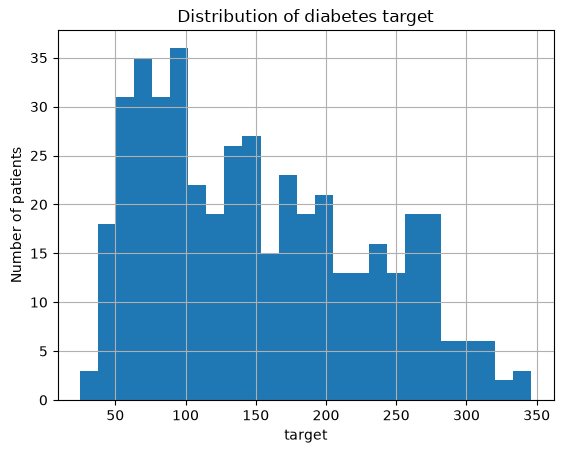

In [15]:
diabetes["target"].hist(bins=25)
plt.xlabel("target")
plt.ylabel("Number of patients")
plt.title("Distribution of diabetes target")
plt.show()

/tmp/ipykernel_5721/517713938.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).groupby("age_group"):


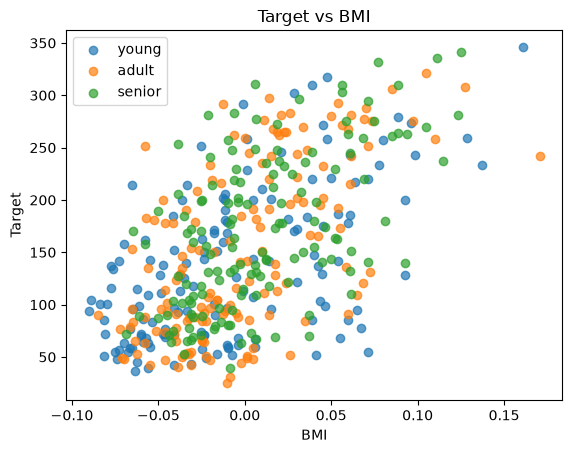

In [42]:
age_group_colors = {}
for patients, group in diabetes.dropna(
    subset=["target", "bmi", "s1", "s2", "s3", "s4", "s5", "s6"]
).groupby("age_group"):
    plt.scatter(group["bmi"], group["target"], label=patients, alpha=0.7)

plt.xlabel("BMI")
plt.ylabel("Target")
plt.title("Target vs BMI")
plt.legend()
plt.show()

Biological question: Does the change in target value change with BMI, and is there any relation with age group?

Answer: there is a clear positive trend and the age groups overlap

/tmp/ipykernel_5721/3318036258.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).groupby("age_group"):


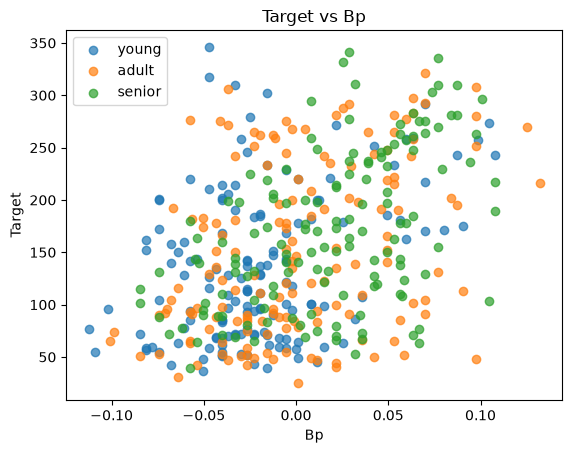

In [43]:
age_group_colors = {}
for patients, group in diabetes.dropna(
    subset=["target", "bmi", "s1", "s2", "s3", "s4", "s5", "s6"]
).groupby("age_group"):
    plt.scatter(group["bp"], group["target"], label=patients, alpha=0.7)

plt.xlabel("Bp")
plt.ylabel("Target")
plt.title("Target vs Bp")
plt.legend()
plt.show()

Biological question: Does the change in target value change with Bp, and is there any relation with age group?

Answer: no distinctive patterns patterns. Maybe a little bit of libear relation between age group and bp.

/tmp/ipykernel_5721/1414963754.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).groupby("age_group"):


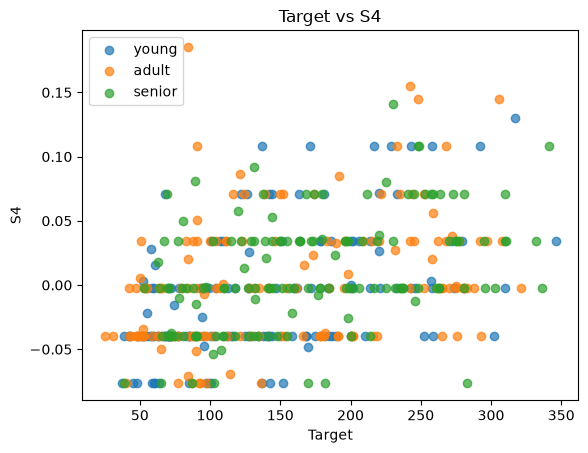

In [40]:
age_group_colors = {}
for patients, group in diabetes.dropna(
    subset=["target", "bmi", "s1", "s2", "s3", "s4", "s5", "s6"]
).groupby("age_group"):
    plt.scatter(group["target"], group["s4"], label=patients, alpha=0.7)

plt.xlabel("Target")
plt.ylabel("S4")
plt.title("Target vs S4")
plt.legend()
plt.show()

Biological question: Does the change in target value change with S4 measurment, and is there any relation with age group?

Answer: S4s few distinct values limit its resolution

### 3.3 Correlation

- Calculate correlation using ar least 2 different methods.
- Identify the predictor most strongly correlated with the target. `BMI and S5`
- Compare results.
- Explain why correlation is not sufficient for feature selection or causal interpretation. `Correlation doesn't mean causation. We can't say that the change in X was due to Y effect, or because Y affected Z, which affected X. Correlation looks at one predictor at a time, which could also carry redundant information. Moreover, for example Pearson correlation only captures linear relationships. Thus correlation isn't sufficient for feature selection`

In [45]:
# Pearson correlation
corr_df = X_all.dropna()
corr_df.corr(method="pearson")

,age,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
bmi,0.185085,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483
target,0.187889,0.586450,0.441482,0.212022,0.174054,-0.394789,0.430453,0.565883,0.382483,1.000000


The target values have the strongest correlations with BMI and S5, before them are bp and s4 measurment with positive correlation and s3 with negative one.
There are weak correlations in the dataset according for the age. S1 and S2 measurments have strong positive correlation. S4 has medium strong positive correlation with s2 and s5 (which isn't weird cause they are all about cholecterol and TGs levels).

In [46]:
# Spearman correlation
corr_df.corr(method="spearman")

,age,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.200554,0.350859,0.262524,0.221711,-0.106973,0.221017,0.265176,0.296235,0.197822
bmi,0.200554,1.000000,0.397985,0.287829,0.295494,-0.371172,0.459068,0.491609,0.384664,0.561382
bp,0.350859,0.397985,1.000000,0.275224,0.205638,-0.191033,0.280799,0.396071,0.381219,0.416241
s1,0.262524,0.287829,0.275224,1.000000,0.878793,0.015308,0.520674,0.512864,0.332173,0.232429
s2,0.221711,0.295494,0.205638,0.878793,1.000000,-0.197435,0.652283,0.349947,0.286483,0.195834
s3,-0.106973,-0.371172,-0.191033,0.015308,-0.197435,1.000000,-0.789694,-0.450420,-0.290863,-0.410022
s4,0.221017,0.459068,0.280799,0.520674,0.652283,-0.789694,1.000000,0.640390,0.413700,0.448931
s5,0.265176,0.491609,0.396071,0.512864,0.349947,-0.450420,0.640390,1.000000,0.453023,0.589416
s6,0.296235,0.384664,0.381219,0.332173,0.286483,-0.290863,0.413700,0.453023,1.000000,0.350792
target,0.197822,0.561382,0.416241,0.232429,0.195834,-0.410022,0.448931,0.589416,0.350792,1.000000


Spearman coefficient gave almost the same results with only subtle changes.

In [48]:
# Distance correlation
target = "target"
features = ["age", "bmi", "bp", "s1", "s2", "s3", "s4", "s5", "s6"]
dcor_results = []
for feature in features:
    pair = corr_df[[feature, target]].dropna()
    dcor_results.append({
        "feature": feature,
        "Distance correlation": dcor.distance_correlation(
            pair[feature].to_numpy(), pair[target].to_numpy()),})

pd.DataFrame(dcor_results).set_index("feature").round(3)

,Distance correlation
feature,
age,0.187
bmi,0.548
bp,0.424
s1,0.227
s2,0.193
s3,0.390
s4,0.422
s5,0.565
s6,0.350


The results obtained from the distance correlation analysis are very similar.

### 4.4 Simple regression

Choose one predictor and fit a simple linear regression. Report and interpret:

- intercept;
- slope;
- the scale of the predictor;
- whether the slope is a causal effect.

In [56]:
simple_df = diabetes[["bmi", "target"]].dropna()

X_simple = simple_df[["bmi"]]
y_simple = simple_df["target"]

simple_model = LinearRegression()
simple_model.fit(X_simple, y_simple)

print("Intercept:", simple_model.intercept_)
print("Slope:", simple_model.coef_[0])

Intercept: 152.13348416289617
Slope: 949.4352603840387


Intercept (152.1): predicted progression at average BMI, since BMI is centered. It equals the target mean. 
Slope (949 per scaled unit): one unit is about 21 SD, so per SD of BMI it is about +45 points

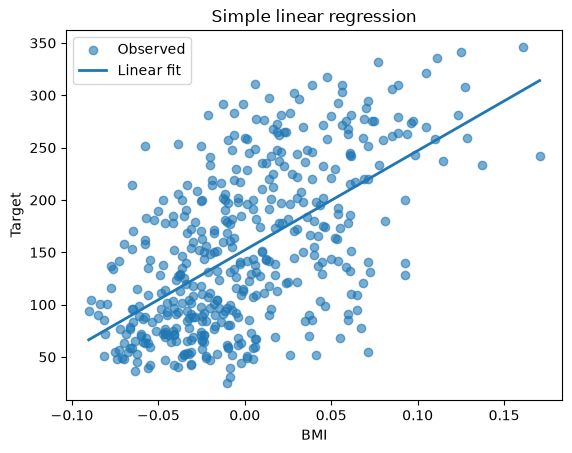

In [55]:
y_hat_simple = simple_model.predict(X_simple)

order = np.argsort(X_simple["bmi"].to_numpy())

plt.scatter(X_simple["bmi"], y_simple, alpha=0.6, label="Observed")

plt.plot(X_simple["bmi"].to_numpy()[order], y_hat_simple[order], linewidth=2, label="Linear fit")

plt.xlabel("BMI")
plt.ylabel("Target")
plt.title("Simple linear regression")
plt.legend()
plt.show()

### 4.5 Residual diagnostics

Produce:

- observed versus predicted plot;
- residuals versus fitted plot;
- residual histogram;
- Q-Q plot.

Discuss linearity, homoscedasticity, residual normality, unusual observations, and any limitations of the diagnostics.

`Residuals seems to be not absolutely linear, and also they have a bit funnel shaped variance distribution. The distribution of the residuals seems to be pretty normal, although it seems that there is a trend to multimodal distribution with one peak in the negative values, and the other one on the positive ones. But looking at the Q-Q plot I could rather say it is a noise`

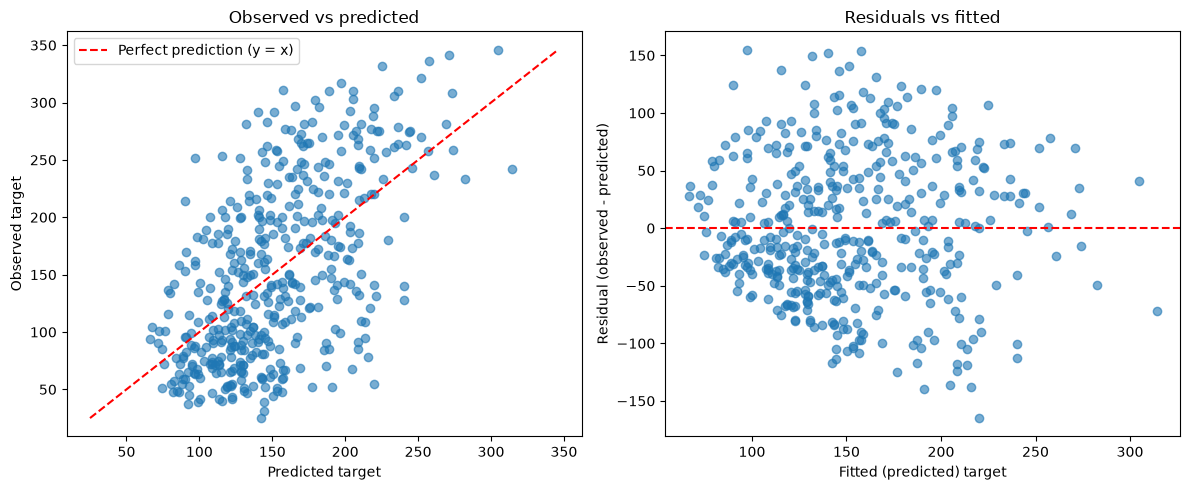

In [60]:
residuals = y_simple.to_numpy() - y_hat_simple
y_true = y_simple.to_numpy()
y_pred = np.asarray(y_hat_simple)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.scatter(y_pred, y_true, alpha=0.6)
lims = [min(y_pred.min(), y_true.min()), max(y_pred.max(), y_true.max())]
ax.plot(lims, lims, "r--", label="Perfect prediction (y = x)")
ax.set_xlabel("Predicted target")
ax.set_ylabel("Observed target")
ax.set_title("Observed vs predicted")
ax.legend()

ax = axes[1]
ax.scatter(y_pred, residuals, alpha=0.6)
ax.axhline(0, color="r", linestyle="--")
ax.set_xlabel("Fitted (predicted) target")
ax.set_ylabel("Residual (observed - predicted)")
ax.set_title("Residuals vs fitted")

plt.tight_layout()
plt.show()

In [57]:
residual_df = pd.DataFrame({
    "observed": y_simple.to_numpy(),
    "predicted": y_hat_simple,
    "residual": residuals})

residual_df.head()

,observed,predicted,residual
0,151.0,210.710038,-59.710038
1,75.0,103.262195,-28.262195
2,141.0,194.337033,-53.337033
3,206.0,141.124769,64.875231
4,135.0,117.588574,17.411426


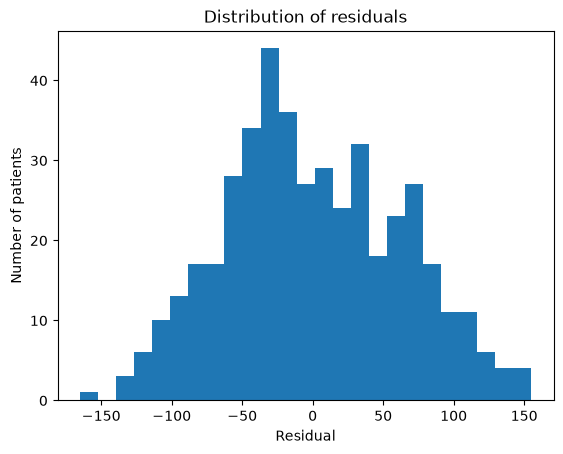

In [63]:
plt.hist(residuals, bins=25)
plt.xlabel("Residual")
plt.ylabel("Number of patients")
plt.title("Distribution of residuals")
plt.show()

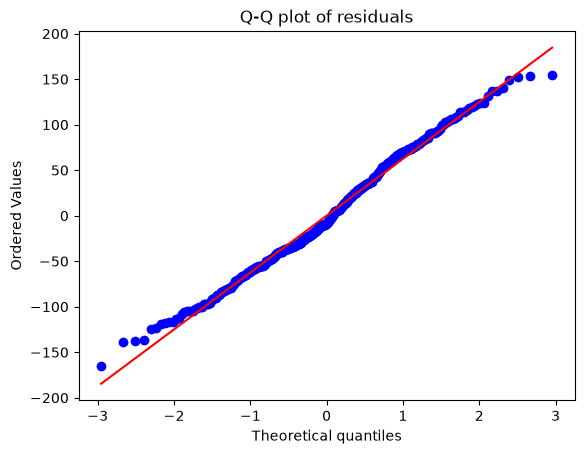

In [64]:
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q plot of residuals")
plt.show()

### 4.6 Multiple regression and multicollinearity

Fit a model using all available predictors. Inspect:

- coefficients;
- predictor correlations;
- possible multicollinearity;
`There is a big correlation between s1 and s2, also s3 and s4, and s2 and s4. Those measurments also have high or elevated variance inflation factor. All together indicates multicollinearity among this measures.`
- whether standardized predictors change coefficient interpretation.
`Since the standardized predictors have the same magnitude we can compare coefficient between preedictors. Also, since predictors are centered, the intercept is just the mean of a target. And talking about the slope we should understand that the predictors are unitles, thus we can't talk about target changes per 1 unit, so per-1-SD representation is more meaningful. This isn't a case when we add encoded categorical predictors`

In [97]:
model_df = diabetes[
    ["bmi", 
     "bp", 
     "s1", 
     "s2", 
     "s3", 
     "s4", 
     "s5", 
     "s6",
     "sex", 
     "age_group", 
     "target"]].dropna()

X = model_df.drop(columns="target")
y = model_df["target"]

numeric_features = ["bmi", 
     "bp", 
     "s1", 
     "s2", 
     "s3", 
     "s4", 
     "s5", 
     "s6"]

categorical_features = ["sex", 
     "age_group"]

preprocessor = ColumnTransformer(
    transformers=[("num", "passthrough", numeric_features),
        ("cat",OneHotEncoder(drop="first", handle_unknown="ignore"),categorical_features)])

full_model = Pipeline(
    steps=[("preprocess", preprocessor),
        ("model", LinearRegression())])

full_model.fit(X, y)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['bmi','bp','s1',...,'s6','sex','age_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the outp

In [104]:
print("Intercept:", full_model.named_steps["model"].intercept_)

Intercept: 136.47464033852685


In [102]:
feature_names = full_model.named_steps["preprocess"].get_feature_names_out()

coefficients = full_model.named_steps["model"].coef_

pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients})

,feature,coefficient
0,num__bmi,517.242289
1,num__bp,320.938336
2,num__s1,-804.613883
3,num__s2,484.422760
4,num__s3,103.086170
5,num__s4,179.917078
6,num__s5,752.532996
7,num__s6,67.178573
8,cat__sex_sex_2,23.651782
9,cat__age_group_senior,5.710197


s1 is -805 and s2 is +484, opposite signs from collinear variables. s1 is also negative even though its raw correlation with the target is +0.21, which signals instability.

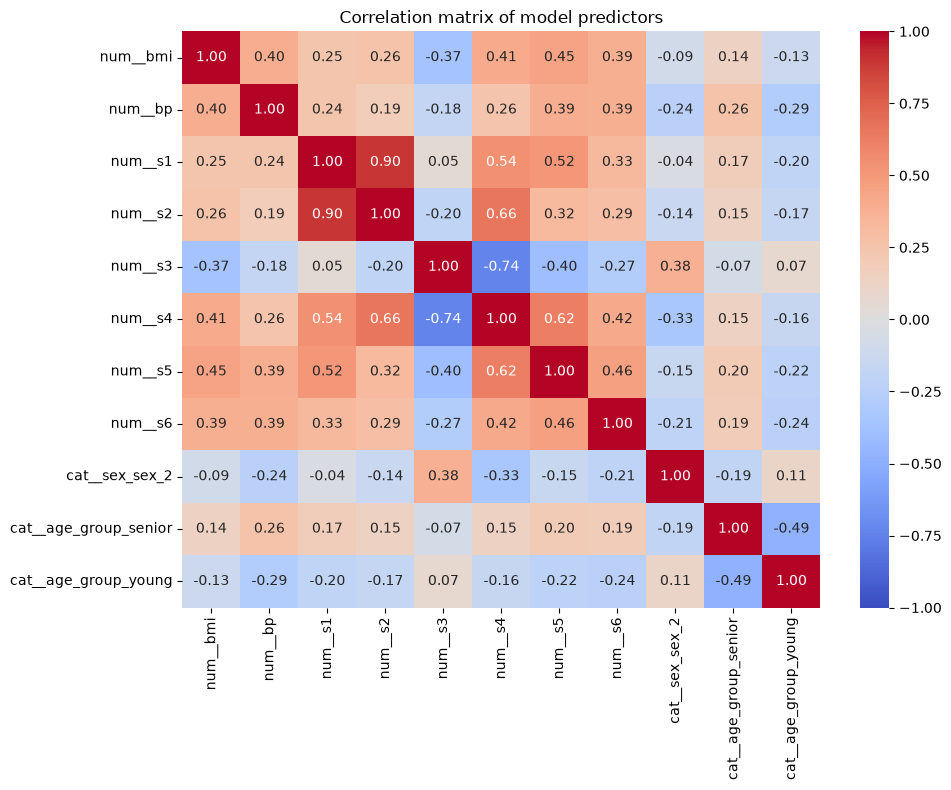

In [106]:
import seaborn as sns

X_transformed = pd.DataFrame(
    full_model.named_steps["preprocess"].transform(X),
    columns=feature_names,
    index=X.index,
)
corr = X_transformed.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix of model predictors")
plt.tight_layout()
plt.show()

In [107]:
vif = {}
for column in X_transformed.columns:
    other_features = X_transformed.drop(columns=column)
    auxiliary_model = LinearRegression().fit(other_features, X_transformed[column])
    r_squared = auxiliary_model.score(other_features, X_transformed[column])
    vif[column] = 1 / (1 - r_squared)

vif_table = pd.Series(vif, name="VIF").round(1).sort_values(ascending=False)
vif_table

num__s1                  59.3
num__s2                  39.2
num__s3                  15.4
num__s5                  10.1
num__s4                   8.9
num__bp                   1.5
num__bmi                  1.5
num__s6                   1.5
cat__age_group_senior     1.4
cat__age_group_young      1.4
cat__sex_sex_2            1.3
Name: VIF, dtype: float64

### 4.7 Train/test evaluation

Create a justified train/test split and report MAE, MSE, RMSE, and $R^2$. Compare simple and multiple regression on test data.

Explain whether the split answers the intended biological or clinical generalization question.

In [108]:
evaluation_df = diabetes.dropna()

X = evaluation_df.drop(columns="target")
y = evaluation_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE)

In [88]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)}

In [110]:
results = []
# Model 1: linear regression
m1 = LinearRegression()
m1.fit(X_train[["bmi"]], y_train)

for split_name, X_split, y_split in [
    ("train", X_train, y_train),
    ("test", X_test, y_test)]:
    pred = m1.predict(X_split[["bmi"]])
    metrics = regression_metrics(y_split, pred)
    results.append({
        "model": "BMI only",
        "split": split_name,
        **metrics })
pd.DataFrame(results).round(2)

,model,split,MAE,MSE,RMSE,R2
0,BMI only,train,51.60,3867.30,62.19,0.34
1,BMI only,test,52.68,3983.86,63.12,0.36


In [111]:
# Model 2: multiple regression with preprocessing fitted on training data
m2 = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LinearRegression()),
    ]
)
m2.fit(X_train, y_train)

for split_name, X_split, y_split in [
    ("train", X_train, y_train),
    ("test", X_test, y_test),
]:
    pred = m2.predict(X_split)
    metrics = regression_metrics(y_split, pred)
    results.append({
        "model": "Multiple regression",
        "split": split_name,
        **metrics,
    })
pd.DataFrame(results).round(2)

,model,split,MAE,MSE,RMSE,R2
0,BMI only,train,51.60,3867.30,62.19,0.34
1,BMI only,test,52.68,3983.86,63.12,0.36
2,Multiple regression,train,42.45,2709.86,52.06,0.54
3,Multiple regression,test,47.03,3475.39,58.95,0.44


### 4.8 Independent-task conclusion

Answer:

1. Which model generalized better?
`The multiple regression: on the test set R^2 was 0.44 vs 0.36, MAE 47 vs 53 and RMSE 59 vs 63. The gap is moderate and rests on 89 test patients, so a single split is noisy.`
1. Did adding more variables help?
`Yes, modestly. Test R² rose from 0.36 to 0.44, though train R² (0.54) exceeds test R², so some overfitting.`
2. Are any regression assumptions questionable?
`Linearity is imperfect, heteroscedasticity is mild at most, and residuals are roughly symmetric. The clearest problem is multicollinearity (VIF 59 for s1, 39 for s2).`
3. Are coefficient interpretations straightforward?
`No. Collinear predictors get unstable coefficients (s1 negative, s2 positive). Predictors are unitless, so “per unit” is meaningless and per-SD values must be used.`
4. What is one important limitation of the dataset or model?
`A single observational cohort of 442 patients, with unrecorded treatments and no external validation. The model can’t support causal claims or generalization to other populations, and even the best model explains under half the variation (test R^2 approx. 0.44).`

Remember that the predictors from `load_diabetes()` are already standardized.